# 04 — Pilot imputasi SO₂ Way Urang

Pilot sementara, bukan pemilihan stasiun final. Acuan: rancangan tahap ketiga dan hasil audit.
Eksperimen hanya menilai rekonstruksi SO₂ yang sengaja disembunyikan pada validasi.
Split kronologis 70/15/15 berdasarkan slot waktu; test hanya diinventarisasi, tidak dievaluasi.
Data test telah tercakup audit sebelumnya. Tidak ada forecasting dilatih.

Implementasi dapat ditinjau di `scripts/pilot_way_urang.py`. Sumber dan seluruh penanda
kualitas tetap dipertahankan; off-grid dipisahkan tanpa pembulatan.


In [1]:
from pathlib import Path
import sys, os
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'outputs/.mplconfig'))
from IPython.display import display,Markdown,Image
import pandas as pd
from pilot_way_urang import Pilot
print('Interpreter:',sys.executable)
pilot=Pilot().prepare()
display(pd.DataFrame(pilot.split))
display(pd.DataFrame(pilot.quality))
display(pilot.offgrid)
display(pd.DataFrame(pilot.feature_info))

Interpreter: C:\Users\INTAN\airpollutan_SO2\.venv\Scripts\python.exe
Persiapan selesai: [{'Split': 'train', 'Awal': Timestamp('2025-01-01 00:00:00'), 'Akhir': Timestamp('2026-03-16 23:00:00'), 'Jumlah slot': 21119, 'Jumlah baris sumber': 20915, 'SO2 nonkosong asli': 19197, 'Status': 'Digunakan sesuai kontrak'}, {'Split': 'validation', 'Awal': Timestamp('2026-03-16 23:30:00'), 'Akhir': Timestamp('2026-06-19 06:00:00'), 'Jumlah slot': 4526, 'Jumlah baris sumber': 4525, 'SO2 nonkosong asli': 4524, 'Status': 'Digunakan sesuai kontrak'}, {'Split': 'test', 'Awal': Timestamp('2026-06-19 06:30:00'), 'Akhir': Timestamp('2026-09-21 13:00:00'), 'Jumlah slot': 4526, 'Jumlah baris sumber': 4525, 'SO2 nonkosong asli': 4525, 'Status': 'Hanya inventaris, tidak dievaluasi'}]


,Split,Awal,Akhir,Jumlah slot,Jumlah baris sumber,SO2 nonkosong asli,Status
0,train,2025-01-01 00:00:00,2026-03-16 23:00:00,21119,20915,19197,Digunakan sesuai kontrak
1,validation,2026-03-16 23:30:00,2026-06-19 06:00:00,4526,4525,4524,Digunakan sesuai kontrak
2,test,2026-06-19 06:30:00,2026-09-21 13:00:00,4526,4525,4525,"Hanya inventaris, tidak dievaluasi"


,Keputusan,Status
0,Off-grid,"Satu baris 2025-05-22 19:01:00, SO2 kosong. Le..."
1,Ketersediaan kovariat,Pengukuran bertimestamp <= t-30 menit diasumsi...
2,Validitas sensor,"Belum dikonfirmasi: kode/nilai 0.01, lonjakan,..."
3,Kebenaran evaluasi,"Nilai asli teramati, bukan jaminan lolos valid..."
4,Test,Sudah tercakup audit tahap sebelumnya; pada pi...


,Baris Excel,Waktu,PM10,PM2.5,SO2,CO,O3,NO2,Kec.Angin,Arah Angin,Kelembaban,Suhu,Tek.Udara,Sol.Rad,Curah Hujan,Timestamp audit
6614,6624,2025-05-22 19:01:00,None,None,None,None,None,None,None,None,None,None,None,None,None,2025-05-22 19:01:00


,Fitur,Lag slot,Nonkosong train,Denominator slot train,Train teramati persen,Nilai unik train,Dipakai P2 dan P3,Alasan
0,PM10,1,19187,21119,90.851840,3286,True,"Numerik, bervariasi dan tersedia pada train; h..."
1,PM2.5,1,19183,21119,90.832899,2671,True,"Numerik, bervariasi dan tersedia pada train; h..."
2,CO,1,19163,21119,90.738198,6332,True,"Numerik, bervariasi dan tersedia pada train; h..."
3,O3,1,19195,21119,90.889720,766,True,"Numerik, bervariasi dan tersedia pada train; h..."
4,NO2,1,19196,21119,90.894455,843,True,"Numerik, bervariasi dan tersedia pada train; h..."
5,Kec.Angin,1,19196,21119,90.894455,1104,True,"Numerik, bervariasi dan tersedia pada train; h..."
6,Kelembaban,1,19196,21119,90.894455,3427,True,"Numerik, bervariasi dan tersedia pada train; h..."
7,Suhu,1,19196,21119,90.894455,1068,True,"Numerik, bervariasi dan tersedia pada train; h..."
8,Tek.Udara,1,19196,21119,90.894455,4319,True,"Numerik, bervariasi dan tersedia pada train; h..."
9,Sol.Rad,1,17291,21119,81.874142,6668,True,"Numerik, bervariasi dan tersedia pada train; h..."


## Masking yang dapat direproduksi

Seed 11, 23, 47. Titik terpisah dan blok dipilih dari nilai SO₂ asli teramati validasi.
Panjang blok berasal dari distribusi gap train, bukan test. Lokasi sama untuk seluruh metode.
Truth disimpan hanya di ledger penilaian, tidak dimasukkan kembali sebagai fitur/donor.
Kovariat P2/P3 dilag satu slot. Ketersediaan aktual masih bersyarat latensi <=30 menit.


In [2]:
pilot.make_masks()
display(pd.DataFrame(pilot.train_gaps))
display(pd.DataFrame(pilot.events).groupby(['Seed','Pola','Panjang slot']).agg(Jumlah_kejadian=('Kejadian','count'),Jumlah_mask=('Jumlah slot','sum')).reset_index())
display(pd.DataFrame(pilot.mask_ledger).head(10))
display(pd.DataFrame([{'Parameter':k,'Nilai':str(v)} for k,v in pilot.config.items()]))

Masking: 18 skenario; 8205 sel; union 3888


,Awal,Akhir,Jumlah slot,Durasi jam
0,2025-01-01 00:00:00,2025-01-02 11:00:00,71,35.5
1,2025-01-02 15:30:00,2025-01-06 11:00:00,184,92.0
2,2025-01-06 21:30:00,2025-01-09 09:00:00,120,60.0
3,2025-01-09 13:00:00,2025-01-11 14:00:00,99,49.5
4,2025-01-12 03:00:00,2025-01-13 14:00:00,71,35.5
5,2025-01-19 13:00:00,2025-01-21 11:30:00,94,47.0
6,2025-01-21 17:00:00,2025-01-23 17:00:00,97,48.5
7,2025-01-24 08:30:00,2025-02-13 18:30:00,981,490.5
8,2025-03-15 04:00:00,2025-03-17 11:00:00,111,55.5
9,2025-03-27 11:00:00,2025-03-27 11:00:00,1,0.5


,Seed,Pola,Panjang slot,Jumlah_kejadian,Jumlah_mask
0,11,blok,4,30,120
1,11,blok,71,6,426
2,11,blok,97,4,388
3,11,blok,184,2,368
4,11,blok,981,1,981
5,11,titik,1,452,452
6,23,blok,4,30,120
7,23,blok,71,6,426
8,23,blok,97,4,388
9,23,blok,184,2,368


,Mask ID,Skenario,Seed,Pola,Panjang slot,Kejadian,Index validasi,Timestamp,SO2 konstan audit
0,11_titik_1_2469,11_titik_1,11,titik,1,1,2469,2026-05-07 10:00:00,False
1,11_titik_1_2208,11_titik_1,11,titik,1,2,2208,2026-05-01 23:30:00,False
2,11_titik_1_4515,11_titik_1,11,titik,1,3,4515,2026-06-19 01:00:00,False
3,11_titik_1_2416,11_titik_1,11,titik,1,4,2416,2026-05-06 07:30:00,False
4,11_titik_1_253,11_titik_1,11,titik,1,5,253,2026-03-22 06:00:00,False
5,11_titik_1_730,11_titik_1,11,titik,1,6,730,2026-04-01 04:30:00,False
6,11_titik_1_2047,11_titik_1,11,titik,1,7,2047,2026-04-28 15:00:00,False
7,11_titik_1_1046,11_titik_1,11,titik,1,8,1046,2026-04-07 18:30:00,False
8,11_titik_1_4512,11_titik_1,11,titik,1,9,4512,2026-06-18 23:30:00,False
9,11_titik_1_786,11_titik_1,11,titik,1,10,786,2026-04-02 08:30:00,False


,Parameter,Nilai
0,stasiun,Kab. Lampung Selatan Way Urang
1,status,"pilot sementara, bukan stasiun final"
2,split,floor(0.70*N) slot train; floor(0.85*N) kumula...
3,seeds,"[11, 23, 47]"
4,point_fraction,0.1
5,block_lengths_slots,"[4, 71, 97, 184, 981]"
6,block_events,"max(1,min(30,floor(0.10*N_observed_validation/..."
7,block_selection,"truth tersedia seluruh blok, buffer 1 slot ter..."
8,p1_limits_slots,"[1, 4, 71, 97, 184, 981]"
9,p2_k,"[3, 5, 10]"


## Fit pada train saja

P0 median; P1 donor asli sebelumnya dengan batas umur; P2 KNN k=3/5/10;
P3 IterativeImputer–BayesianRidge satu keluaran deterministik.
P2/P3 memakai kovariat lag yang sama dan scaler yang dipelajari dari train.
Waktu mentah dan arah angin linear tidak menjadi fitur. Query SO₂ P2/P3 selalu NaN.


In [3]:
pilot.fit()
display(pd.DataFrame(pilot.params))
display(pd.DataFrame(pilot.scaling))
display(pd.DataFrame([{'Metode':k,'Fit detik':v} for k,v in pilot.fit_times.items()]))

Fit selesai; seluruh parameter dari train, tidak ada test.


,Parameter,Nilai
0,median SO2 train,1.61
1,P3 iterasi nyata,20.00
2,SO2 train minimum,0.92
3,SO2 train maksimum,80.71
4,Jumlah donor KNN SO2 asli train,19197.00


,Fitur,Mean train,Skala train,Jumlah nilai untuk scaler
0,SO2,13.975409,20.392788,19197
1,PM10,14.020730,9.922839,19187
2,PM2.5,10.516663,7.645737,19183
3,CO,307.205558,146.845737,19163
4,O3,9.616332,10.926841,19195
5,NO2,8.650471,3.356818,19196
6,Kec.Angin,4.768936,12.076456,19196
7,Kelembaban,83.620844,7.350981,19196
8,Suhu,28.236255,2.271461,19196
9,Tek.Udara,986.536350,29.824244,19196


,Metode,Fit detik
0,P0,0.000529
1,P1_L1,0.000000
2,P1_L4,0.000000
3,P1_L71,0.000000
4,P1_L97,0.000000
5,P1_L184,0.000000
6,P1_L981,0.000000
7,P2_k3,0.001638
8,P2_k5,0.001556
9,P2_k10,0.001626


## Evaluasi validasi

Bias = prediksi − pengamatan asli; MAE/RMSE dalam µg/m³.
Cakupan = prediksi finite / jumlah nilai sengaja disembunyikan × 100%.
Nilai hilang alami tidak menjadi truth. Semua metode memakai ledger mask yang identik.
Irisan seluruh konfigurasi dapat sangat kecil pada blok panjang karena P1 L=1.
Transform setiap skenario dijalankan dan diukur terpisah; tidak memakai cache prediksi.


,Metode,Seed,Pola,Panjang slot,Panjang jam,Domain,Jumlah mask,Jumlah dinilai,Cakupan persen,MAE,RMSE,Bias,Fit detik,Scaler fit detik bersama,Transform detik,Prediksi negatif,Di luar rentang SO2 train
0,P0,11,titik,1,0.5,seluruh berhasil,452,452,100.000000,0.088274,0.110975,0.048407,0.000529,0.00000,0.000034,0,0
1,P0,11,titik,1,0.5,irisan semua metode,452,452,100.000000,0.088274,0.110975,0.048407,0.000529,0.00000,0.000034,0,0
2,P1_L1,11,titik,1,0.5,seluruh berhasil,452,452,100.000000,0.115243,0.145979,-0.001350,0.000000,0.00000,0.038010,0,0
3,P1_L1,11,titik,1,0.5,irisan semua metode,452,452,100.000000,0.115243,0.145979,-0.001350,0.000000,0.00000,0.038010,0,0
4,P1_L4,11,titik,1,0.5,seluruh berhasil,452,452,100.000000,0.115243,0.145979,-0.001350,0.000000,0.00000,0.037971,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
391,P2_k5,47,blok,981,490.5,irisan semua metode,981,1,0.101937,0.136420,0.136420,0.136420,0.001556,0.02629,1.540061,0,0
392,P2_k10,47,blok,981,490.5,seluruh berhasil,981,981,100.000000,0.089990,0.114554,0.005138,0.001626,0.02629,1.663198,0,0
393,P2_k10,47,blok,981,490.5,irisan semua metode,981,1,0.101937,0.119126,0.119126,0.119126,0.001626,0.02629,1.663198,0,0
394,P3,47,blok,981,490.5,seluruh berhasil,981,981,100.000000,2.342109,3.526453,1.397919,3.227640,0.02629,0.099983,79,180


,Metode,Pola,Panjang slot,Domain,Jumlah seed,MAE rata-rata,MAE SD antar-seed,MAE minimum,MAE maksimum,RMSE rata-rata,RMSE SD antar-seed,Bias rata-rata,Bias SD antar-seed,Cakupan persen rata-rata,Cakupan persen SD antar-seed,Cakupan persen minimum,Cakupan persen maksimum,Jumlah dinilai rata-rata,Jumlah dinilai SD antar-seed,Transform detik rata-rata,Transform detik SD antar-seed
0,P0,titik,1,seluruh berhasil,3,0.093053,0.009054,0.087389,0.103496,0.117482,0.014766,0.052404,0.003547,100.000000,0.000000,100.000000,100.000000,452.000000,0.00000,0.000019,0.000013
1,P0,titik,1,irisan semua metode,3,0.093044,0.009063,0.087361,0.103496,0.117488,0.014761,0.052518,0.003611,99.926254,0.127732,99.778761,100.000000,451.666667,0.57735,0.000019,0.000013
2,P1_L1,titik,1,seluruh berhasil,3,0.118461,0.007688,0.112905,0.127235,0.149752,0.008936,0.003059,0.004986,99.926254,0.127732,99.778761,100.000000,451.666667,0.57735,0.027898,0.009377
3,P1_L1,titik,1,irisan semua metode,3,0.118461,0.007688,0.112905,0.127235,0.149752,0.008936,0.003059,0.004986,99.926254,0.127732,99.778761,100.000000,451.666667,0.57735,0.027898,0.009377
4,P1_L4,titik,1,seluruh berhasil,3,0.118532,0.007611,0.113119,0.127235,0.149812,0.008871,0.002898,0.004725,100.000000,0.000000,100.000000,100.000000,452.000000,0.00000,0.027871,0.009370
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,P2_k5,blok,981,irisan semua metode,3,0.139486,0.041937,0.099166,0.182871,0.139486,0.041937,0.139486,0.041937,0.101937,0.000000,0.101937,0.101937,1.000000,0.00000,1.509775,0.036932
128,P2_k10,blok,981,seluruh berhasil,3,0.091746,0.003189,0.089821,0.095426,0.118056,0.006004,0.000558,0.006294,100.000000,0.000000,100.000000,100.000000,981.000000,0.00000,1.674992,0.095022
129,P2_k10,blok,981,irisan semua metode,3,0.126772,0.062217,0.068732,0.192460,0.126772,0.062217,0.126772,0.062217,0.101937,0.000000,0.101937,0.101937,1.000000,0.00000,1.674992,0.095022
130,P3,blok,981,seluruh berhasil,3,2.012339,0.586688,1.334969,2.359940,2.968745,0.972458,1.196539,0.370229,100.000000,0.000000,100.000000,100.000000,981.000000,0.00000,0.110394,0.013683


,Skenario,Seed,Pola,Panjang slot,Jumlah mask,Irisan semua metode,Irisan persen
0,11_titik_1,11,titik,1,452,452,100.000000
1,11_blok_4,11,blok,4,120,30,25.000000
2,11_blok_71,11,blok,71,426,6,1.408451
3,11_blok_97,11,blok,97,388,4,1.030928
4,11_blok_184,11,blok,184,368,2,0.543478
5,11_blok_981,11,blok,981,981,1,0.101937
6,23_titik_1,23,titik,1,452,452,100.000000
7,23_blok_4,23,blok,4,120,30,25.000000
8,23_blok_71,23,blok,71,426,6,1.408451
9,23_blok_97,23,blok,97,388,4,1.030928


,Metode,Tahap,Kategori,Pesan
0,P3,fit,ConvergenceWarning,[IterativeImputer] Early stopping criterion no...


""


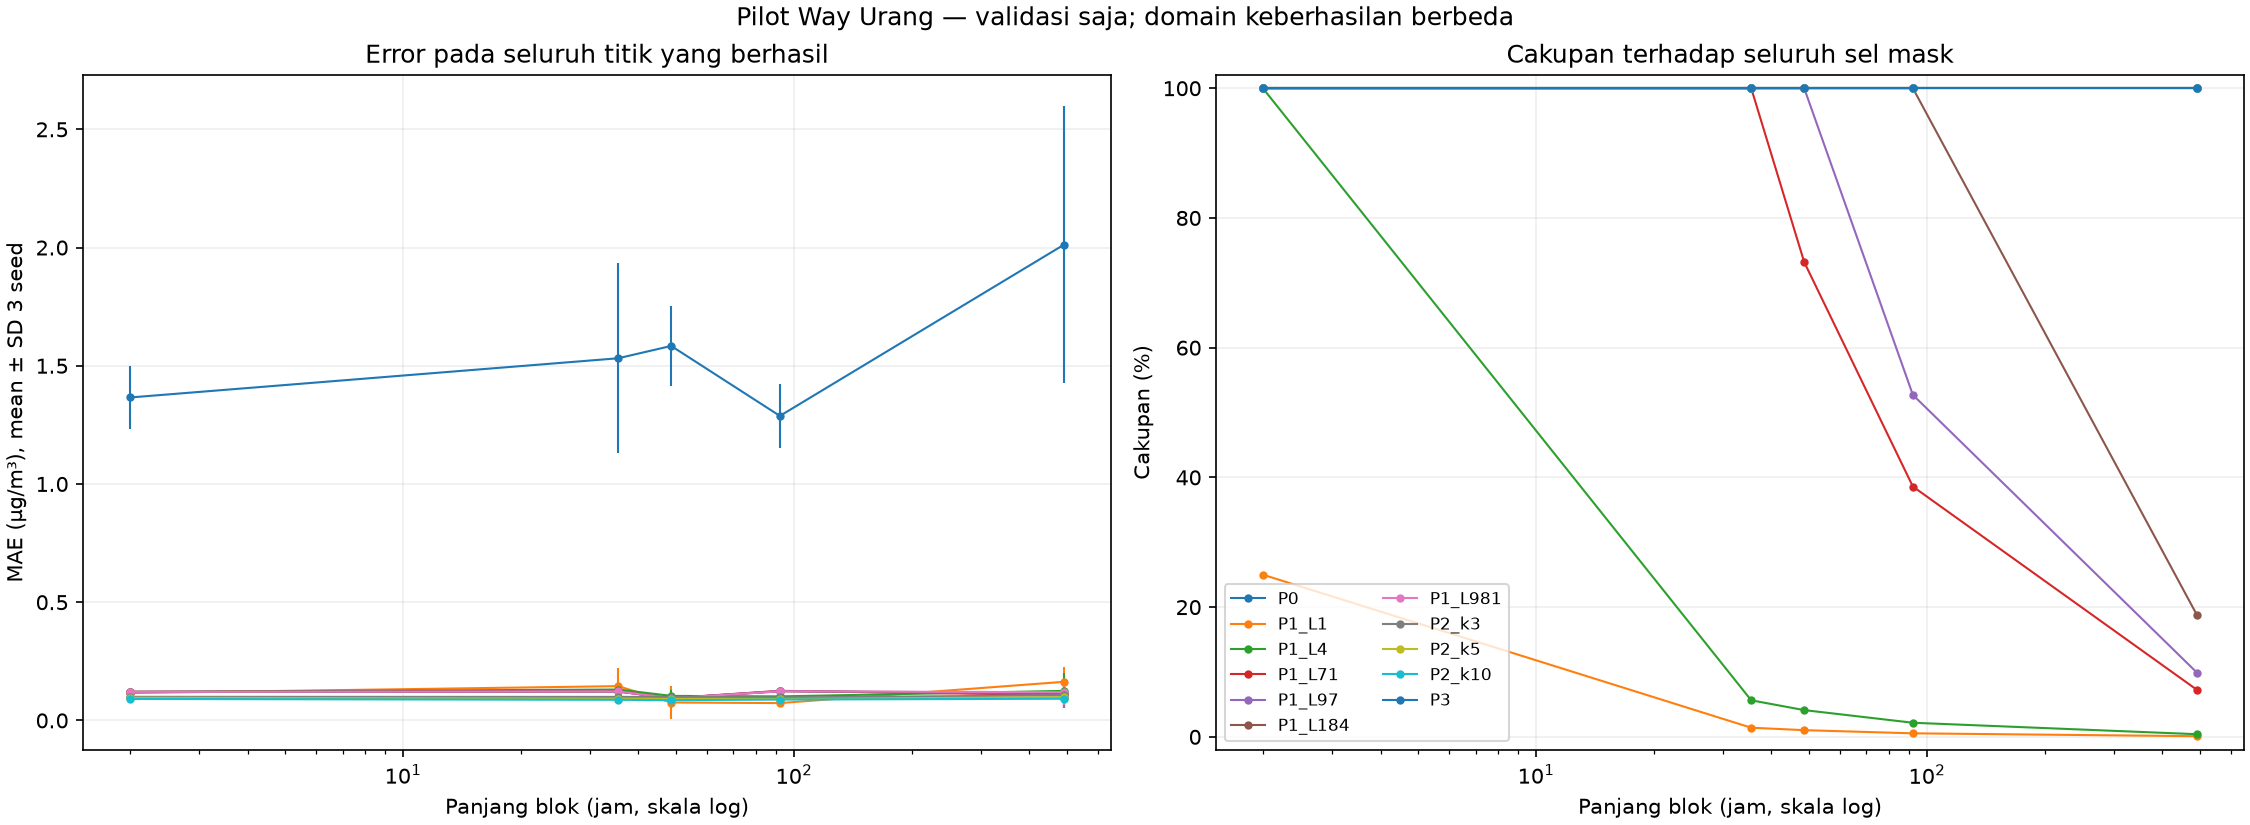

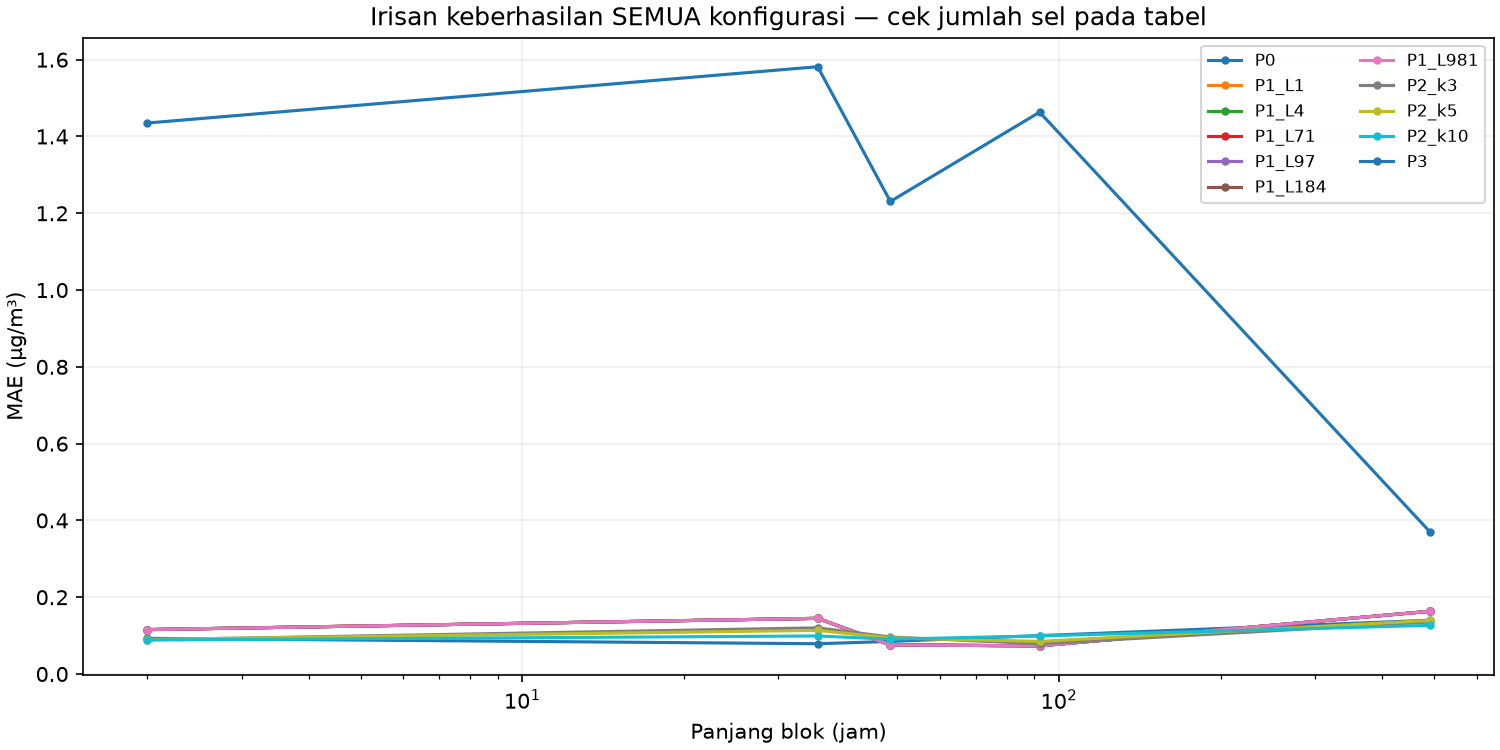

,File,SHA256 sebelum,SHA256 sesudah,Identik
0,data_raw\Telkom University Purwokerto - Intan ...,bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8...,bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8...,True
1,outputs\rancangan_eksperimen_preprocessing.md,d256294ac4568c82cbfeb9e06006b435dce293f52533bb...,d256294ac4568c82cbfeb9e06006b435dce293f52533bb...,True
2,outputs\audit_kualitas_tables.json,89bf7a39781e9ea3368a8c7a4731cf7c8c36523eb117a2...,89bf7a39781e9ea3368a8c7a4731cf7c8c36523eb117a2...,True
3,outputs\pemeriksaan_lanjutan_tables.json,4cb3f7885064fd943ef5efdc1f0e4fdd7448e2587467f9...,4cb3f7885064fd943ef5efdc1f0e4fdd7448e2587467f9...,True
4,outputs\audit_grids\02_grid_audit.csv,b438ed9dd3308256071016b37d5df59208df0f961fc916...,b438ed9dd3308256071016b37d5df59208df0f961fc916...,True


In [4]:
pilot.evaluate()
display(pd.DataFrame(pilot.metrics))
display(pd.DataFrame(pilot.summary))
display(pd.DataFrame(pilot.intersections))
display(pd.DataFrame(pilot.warn))
display(pd.DataFrame(pilot.failures))
for name in ['error_dan_cakupan_blok.png','error_irisan_semua_metode.png']:
    display(Image(filename=str(ROOT/'outputs/figures/pilot_way_urang'/name)))
display(pd.DataFrame(pilot.integrity))

## Ekspor dan kesimpulan terbatas

Workbook memuat skor per seed/pola/panjang/domain, ringkasan variasi, cakupan,
lokasi mask, konfigurasi parameter train, penanda kualitas dan hash sumber.
Prediksi lengkap dan truth terpisah tersedia pada `outputs/pilot_way_urang/`.
Keunggulan rekonstruksi pada pilot ini belum menjadi keunggulan forecasting.


In [5]:
pilot.export_excel()
report=(ROOT/'outputs/ringkasan_pilot_imputasi_way_urang.md').read_text(encoding='utf-8')
display(Markdown(report.replace('(figures/', '(../outputs/figures/')))
print('Selesai. Test akhir tidak dievaluasi. Tidak ada model forecasting dilatih.')

{"kind":"table","sheet":"Ringkasan","address":"A1:F4","rows":4,"cols":6,"values":[["Metode","Pola","Panjang slot","Domain","Jumlah seed","MAE rata-rata"],["P0","titik",1,"seluruh berhasil",3,0.09305309734513274],["P0","titik",1,"irisan semua metode",3,0.09304377685772032],["P1_L1","titik",1,"seluruh berhasil",3,0.11846084414182838]]}
Inspect result written to file: C:\Users\INTAN\airpollutan_SO2\outputs\pilot_imputasi_way_urang.xlsx.inspect.ndjson
Ekspor selesai: 19 sheet.

Selesai. Test akhir tidak dievaluasi. Tidak ada model forecasting dilatih.


# Pilot imputasi SO₂ — Lampung Selatan Way Urang

**Pilot sementara; bukan pemilihan stasiun final dan bukan eksperimen forecasting.** P0–P3 dibandingkan pada validasi saja. Pengujian akhir tidak ditransformasi, tidak diberi skor, dan tidak digunakan untuk memilih parameter. Data tersebut telah tercakup audit sebelumnya, sehingga tidak disebut sama sekali belum pernah dilihat.

## 1. Data, kualitas dan keputusan yang belum ditetapkan

- Sumber dibaca tanpa perubahan. Salinan seluruh baris, grid audit dan penanda kualitas ada di `pilot_way_urang/`. Nol, lonjakan, rentetan konstan dan ekstrem tidak dihapus. Penanda audit tetap disimpan; tidak digunakan sebagai label sensor rusak.
- Terdapat **satu baris off-grid: 2025-05-22 19:01:00, SO₂ kosong**. Baris dipertahankan pada `offgrid_asli.csv` dan tidak dibulatkan, diagregasi atau menjadi truth.
- Makna kode/nilai 0.01, validitas sensor, perubahan pola, dan latensi belum dikonfirmasi. Pengamatan asli teramati dipakai sebagai referensi rekonstruksi, bukan sertifikasi nilai valid.
- **Asumsi ketersediaan yang memengaruhi hasil:** kovariat bertimestamp paling lambat t−30 menit diasumsikan telah tiba ketika SO₂ pada t direkonstruksi. Timestamp asli tidak membuktikan latensi. Jika latensi aktual lebih panjang, fitur perlu digeser lagi dan hasil ini harus diuji ulang.
- Skenario pilot menyembunyikan SO₂ saja dan mempertahankan kovariat lag yang asli. Ini rekonstruksi kondisional dengan kovariat tersedia, belum meniru seluruh sensor/baris hilang bersamaan. Tidak ada nilai gap alami dijadikan truth atau diisi sebagai produk akhir.

## 2. Pemisahan waktu 70/15/15

N slot grid reguler dibagi `floor(0.70*N)` untuk train, hingga `floor(0.85*N)` untuk validasi, dan sisanya test. Ini pembagian durasi slot waktu, bukan pengacakan jumlah pengamatan nonkosong. Selisih pembulatan hanya satuan slot.

| Split | Awal | Akhir | Jumlah slot | Jumlah baris sumber | SO2 nonkosong asli | Status |
|---|---|---|---|---|---|---|
| train | 2025-01-01 00:00:00 | 2026-03-16 23:00:00 | 21119 | 20915 | 19197 | Digunakan sesuai kontrak |
| validation | 2026-03-16 23:30:00 | 2026-06-19 06:00:00 | 4526 | 4525 | 4524 | Digunakan sesuai kontrak |
| test | 2026-06-19 06:30:00 | 2026-09-21 13:00:00 | 4526 | 4525 | 4525 | Hanya inventaris, tidak dievaluasi |

Semua median, mean/skala, daftar fitur, donor dan model imputasi berasal dari train. Nilai train lebih awal daripada seluruh query validasi. Bagian test hanya digunakan untuk inventaris pada tabel di atas; tidak ada skor test atau transform test.

## 3. Distribusi gap train dan masking

Distribusi panjang gap dihitung ulang pada **train saja**, termasuk gap awal. Kategori blok bukan batas aman imputasi. Panjang blok yang diuji berasal dari gap 4 slot dan kuantil empiris nearest `{0,0.5,0.9,1}` gap panjang >4 slot.

| Jumlah slot | Durasi jam | Jumlah kejadian |
|---|---|---|
| 1 | 0.50 | 15 |
| 4 | 2.00 | 1 |
| 71 | 35.50 | 2 |
| 75 | 37.50 | 1 |
| 94 | 47.00 | 1 |
| 97 | 48.50 | 1 |
| 99 | 49.50 | 1 |
| 111 | 55.50 | 1 |
| 120 | 60.00 | 1 |
| 184 | 92.00 | 1 |
| 981 | 490.50 | 1 |

Panjang blok: **[4, 71, 97, 184, 981] slot**, atau **[2.0, 35.5, 48.5, 92.0, 490.5] jam**. Tiga seed tetap: **11, 23, 47**. Titik terpisah memakai 10% SO₂ teramati validasi (dibulatkan ke bawah), tanpa pasangan mask bertetangga. Blok memakai `max(1,min(30,floor(0.10*N_teramati/L)))` kejadian, tersedia truth penuh dan buffer satu slot teramati pada kedua sisi, tanpa overlap dalam skenario. Untuk blok 981 slot, satu blok saja melebihi 10%; cakupannya dilaporkan apa adanya.

| Seed | Pola | Panjang slot | Durasi blok jam | Jumlah kejadian | Jumlah nilai disembunyikan | Persen dari SO2 teramati validasi |
|---|---|---|---|---|---|---|
| 11 | titik | 1 | 0.50 | 452 | 452 | 9.991 |
| 11 | blok | 4 | 2.00 | 30 | 120 | 2.653 |
| 11 | blok | 71 | 35.50 | 6 | 426 | 9.416 |
| 11 | blok | 97 | 48.50 | 4 | 388 | 8.576 |
| 11 | blok | 184 | 92.00 | 2 | 368 | 8.134 |
| 11 | blok | 981 | 490.50 | 1 | 981 | 21.684 |
| 23 | titik | 1 | 0.50 | 452 | 452 | 9.991 |
| 23 | blok | 4 | 2.00 | 30 | 120 | 2.653 |
| 23 | blok | 71 | 35.50 | 6 | 426 | 9.416 |
| 23 | blok | 97 | 48.50 | 4 | 388 | 8.576 |
| 23 | blok | 184 | 92.00 | 2 | 368 | 8.134 |
| 23 | blok | 981 | 490.50 | 1 | 981 | 21.684 |
| 47 | titik | 1 | 0.50 | 452 | 452 | 9.991 |
| 47 | blok | 4 | 2.00 | 30 | 120 | 2.653 |
| 47 | blok | 71 | 35.50 | 6 | 426 | 9.416 |
| 47 | blok | 97 | 48.50 | 4 | 388 | 8.576 |
| 47 | blok | 184 | 92.00 | 2 | 368 | 8.134 |
| 47 | blok | 981 | 490.50 | 1 | 981 | 21.684 |

- Lokasi mask sama untuk seluruh konfigurasi pada suatu skenario. Mask antar-seed atau antar-skenario boleh overlap; SD tiga seed bukan interval kepercayaan independen.
- `truth_penilaian_saja.csv` menyimpan nilai asli terpisah. Query P2/P3 selalu SO₂ NaN; donor hanya train. State P1 menerima SO₂ validasi yang tidak dimask hanya setelah waktunya terlewati, dan tidak pernah memakai nilai mask atau nilai imputasi untuk mereset donor.
- Blok besar diletakkan hanya pada segmen yang truth-nya lengkap. Keterwakilan terhadap missing alami panjang/serentak masih terbatas; buffer teramati juga merupakan seleksi skenario dan tidak membuktikan kondisi gap awal tanpa donor.

## 4. Implementasi metode

- **P0:** median SO₂ asli train = **1.61 µg/m³**, tetap untuk semua query.
- **P1:** umur donor maksimum **[1, 4, 71, 97, 184, 981] slot**. Donor adalah pengamatan asli terakhir sebelum slot rekonstruksi. Jika melampaui batas, hasil tetap tidak terisi; panjang gap akhir tidak dilihat untuk menentukan perlakuan slot awal.
- **P2:** `KNNImputer`, k=3/5/10, `weights=distance`, `metric=nan_euclidean`. Donor memiliki SO₂ asli finite dan hanya berasal dari train. SO₂ query seluruhnya NaN sehingga jarak dibentuk hanya dari kovariat lag yang overlap, tanpa waktu mentah atau SO₂ validasi. Minimal dua kovariat asli harus tersedia pada query. Jarak bawaan memakai jumlah overlap yang bisa berbeda antar-pasangan. Query tanpa jarak terdefinisi ditolak, bukan diberi fallback mean tersembunyi.
- **P3:** `IterativeImputer(estimator=BayesianRidge(), max_iter=20, tol=0.001, initial_strategy=median, imputation_order=ascending, random_state=42, sample_posterior=False, skip_complete=False)`. Fit hanya train. Kovariat kosong diperkirakan sementara dalam iterasi berdasarkan model train pada baris query itu, tanpa memakai baris waktu berikutnya. Satu keluaran ini adalah imputasi tunggal deterministik, bukan multiple imputation lengkap.
- **Fitur P2 dan P3 sama:** PM10, PM2.5, CO, O3, NO2, Kec.Angin, Kelembaban, Suhu, Tek.Udara, Sol.Rad, Curah Hujan. Semuanya dilag satu slot; tidak ada SO₂ masa depan, backward fill, interpolasi dua arah, rolling terpusat atau fitur waktu numerik mentah. Arah Angin dikeluarkan dari keduanya agar tidak diperlakukan sebagai variabel linear. Pemilihan fitur memakai dukungan dan variasi train saja, tanpa seleksi berdasarkan korelasi/skor validasi.
- **Scaling:** satu `StandardScaler` fit pada matriks train dengan NaN tetap NaN. Transform memakai mean/skala train, dan SO₂ hasil dikembalikan ke µg/m³. Standardisasi membuat variabel besar seperti CO/tekanan tidak otomatis mendominasi jarak KNN; ekstrem train tetap dapat memengaruhi skala. Tidak ada pembandingan scaler lain pada pilot ini, sehingga efek scaling belum diisolasi secara eksperimen.
- Kolom kosong/konstan train tidak dipakai sebagai kovariat informatif. NaN kovariat tidak diisi dengan nol. P2 memakai overlap; P3 memakai model train. Keduanya ditolak bila kurang dari dua kovariat asli tersedia. Tidak ada clipping hasil.
Implementasi mengacu dokumentasi resmi [KNNImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html), [IterativeImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.IterativeImputer.html), dan [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

| Fitur | Lag slot | Nonkosong train | Train teramati persen | Nilai unik train | Dipakai P2 dan P3 |
|---|---|---|---|---|---|
| PM10 | 1 | 19187 | 90.852 | 3286 | True |
| PM2.5 | 1 | 19183 | 90.833 | 2671 | True |
| CO | 1 | 19163 | 90.738 | 6332 | True |
| O3 | 1 | 19195 | 90.890 | 766 | True |
| NO2 | 1 | 19196 | 90.894 | 843 | True |
| Kec.Angin | 1 | 19196 | 90.894 | 1104 | True |
| Kelembaban | 1 | 19196 | 90.894 | 3427 | True |
| Suhu | 1 | 19196 | 90.894 | 1068 | True |
| Tek.Udara | 1 | 19196 | 90.894 | 4319 | True |
| Sol.Rad | 1 | 17291 | 81.874 | 6668 | True |
| Curah Hujan | 1 | 12689 | 60.083 | 50 | True |

## 5. Hasil validasi

`e = prediksi − pengamatan asli`. MAE=mean(|e|), RMSE=sqrt(mean(e²)), bias=mean(e), dalam µg/m³. Cakupan (%)=100×prediksi finite/jumlah nilai sengaja disembunyikan. N=0 menghasilkan skor kosong, bukan nol. Tidak ada missing alami atau nilai test masuk denominator skor.
Workbook `Hasil_per_seed` memuat hasil setiap seed, pola, panjang blok dan domain. Tabel berikut berisi mean dan SD sampel antar-seed; bukan skor gabungan seluruh seed.

### Seluruh titik yang dapat diisi masing-masing metode

| Metode | Pola | Panjang slot | MAE rata-rata | MAE SD antar-seed | RMSE rata-rata | Bias rata-rata | Cakupan persen rata-rata | Cakupan persen SD antar-seed |
|---|---|---|---|---|---|---|---|---|
| P0 | titik | 1 | 0.093053 | 0.009054 | 0.117482 | 0.052404 | 100.000 | 0.000 |
| P1_L1 | titik | 1 | 0.118461 | 0.007688 | 0.149752 | 0.003059 | 99.926 | 0.128 |
| P1_L4 | titik | 1 | 0.118532 | 0.007611 | 0.149812 | 0.002898 | 100.000 | 0.000 |
| P1_L71 | titik | 1 | 0.118532 | 0.007611 | 0.149812 | 0.002898 | 100.000 | 0.000 |
| P1_L97 | titik | 1 | 0.118532 | 0.007611 | 0.149812 | 0.002898 | 100.000 | 0.000 |
| P1_L184 | titik | 1 | 0.118532 | 0.007611 | 0.149812 | 0.002898 | 100.000 | 0.000 |
| P1_L981 | titik | 1 | 0.118532 | 0.007611 | 0.149812 | 0.002898 | 100.000 | 0.000 |
| P2_k3 | titik | 1 | 0.100811 | 0.007545 | 0.129685 | 0.001646 | 99.926 | 0.128 |
| P2_k5 | titik | 1 | 0.093959 | 0.007862 | 0.121854 | 0.002098 | 99.926 | 0.128 |
| P2_k10 | titik | 1 | 0.089505 | 0.008491 | 0.116131 | 0.003407 | 99.926 | 0.128 |
| P3 | titik | 1 | 1.443547 | 0.114360 | 2.320072 | 0.560138 | 99.926 | 0.128 |
| P0 | blok | 4 | 0.097639 | 0.004568 | 0.123392 | 0.054417 | 100.000 | 0.000 |
| P1_L1 | blok | 4 | 0.115667 | 0.013013 | 0.150649 | -0.010778 | 25.000 | 0.000 |
| P1_L4 | blok | 4 | 0.120750 | 0.007419 | 0.152666 | -0.002139 | 100.000 | 0.000 |
| P1_L71 | blok | 4 | 0.120750 | 0.007419 | 0.152666 | -0.002139 | 100.000 | 0.000 |
| P1_L97 | blok | 4 | 0.120750 | 0.007419 | 0.152666 | -0.002139 | 100.000 | 0.000 |
| P1_L184 | blok | 4 | 0.120750 | 0.007419 | 0.152666 | -0.002139 | 100.000 | 0.000 |
| P1_L981 | blok | 4 | 0.120750 | 0.007419 | 0.152666 | -0.002139 | 100.000 | 0.000 |
| P2_k3 | blok | 4 | 0.099920 | 0.002875 | 0.129550 | 0.010146 | 100.000 | 0.000 |
| P2_k5 | blok | 4 | 0.095950 | 0.002194 | 0.123954 | 0.008364 | 100.000 | 0.000 |
| P2_k10 | blok | 4 | 0.090790 | 0.004581 | 0.117924 | 0.008744 | 100.000 | 0.000 |
| P3 | blok | 4 | 1.365839 | 0.134963 | 1.921252 | 0.519366 | 100.000 | 0.000 |
| P0 | blok | 71 | 0.092660 | 0.004562 | 0.118431 | 0.052551 | 100.000 | 0.000 |
| P1_L1 | blok | 71 | 0.145000 | 0.076884 | 0.179780 | -0.089444 | 1.408 | 0.000 |
| P1_L4 | blok | 71 | 0.130694 | 0.003544 | 0.163126 | -0.055139 | 5.634 | 0.000 |
| P1_L71 | blok | 71 | 0.122543 | 0.014085 | 0.154477 | -0.044671 | 100.000 | 0.000 |
| P1_L97 | blok | 71 | 0.122543 | 0.014085 | 0.154477 | -0.044671 | 100.000 | 0.000 |
| P1_L184 | blok | 71 | 0.122543 | 0.014085 | 0.154477 | -0.044671 | 100.000 | 0.000 |
| P1_L981 | blok | 71 | 0.122543 | 0.014085 | 0.154477 | -0.044671 | 100.000 | 0.000 |
| P2_k3 | blok | 71 | 0.099600 | 0.003909 | 0.130860 | -0.000525 | 100.000 | 0.000 |
| P2_k5 | blok | 71 | 0.092172 | 0.005682 | 0.119848 | 0.000447 | 100.000 | 0.000 |
| P2_k10 | blok | 71 | 0.087201 | 0.004863 | 0.113328 | 0.002513 | 100.000 | 0.000 |
| P3 | blok | 71 | 1.531788 | 0.401604 | 2.263263 | 0.732706 | 100.000 | 0.000 |
| P0 | blok | 97 | 0.089175 | 0.002818 | 0.114216 | 0.051649 | 100.000 | 0.000 |
| P1_L1 | blok | 97 | 0.075833 | 0.070460 | 0.098491 | -0.030833 | 1.031 | 0.000 |
| P1_L4 | blok | 97 | 0.103750 | 0.026272 | 0.130961 | 0.017083 | 4.124 | 0.000 |
| P1_L71 | blok | 97 | 0.094472 | 0.008018 | 0.120861 | 0.020153 | 73.196 | 0.000 |
| P1_L97 | blok | 97 | 0.093875 | 0.008047 | 0.120136 | 0.020816 | 100.000 | 0.000 |
| P1_L184 | blok | 97 | 0.093875 | 0.008047 | 0.120136 | 0.020816 | 100.000 | 0.000 |
| P1_L981 | blok | 97 | 0.093875 | 0.008047 | 0.120136 | 0.020816 | 100.000 | 0.000 |
| P2_k3 | blok | 97 | 0.099414 | 0.001870 | 0.127060 | -0.003225 | 100.000 | 0.000 |
| P2_k5 | blok | 97 | 0.091161 | 0.002843 | 0.117864 | -0.000701 | 100.000 | 0.000 |
| P2_k10 | blok | 97 | 0.085512 | 0.002501 | 0.110952 | -0.000916 | 100.000 | 0.000 |
| P3 | blok | 97 | 1.583851 | 0.167586 | 2.742110 | 0.790615 | 100.000 | 0.000 |
| P0 | blok | 184 | 0.091957 | 0.004451 | 0.118502 | 0.052428 | 100.000 | 0.000 |
| P1_L1 | blok | 184 | 0.073333 | 0.014434 | 0.083535 | -0.050000 | 0.543 | 0.000 |
| P1_L4 | blok | 184 | 0.101667 | 0.007324 | 0.127699 | -0.054167 | 2.174 | 0.000 |
| P1_L71 | blok | 184 | 0.125164 | 0.012219 | 0.154637 | -0.071549 | 38.587 | 0.000 |
| P1_L97 | blok | 184 | 0.124450 | 0.010811 | 0.152104 | -0.073316 | 52.717 | 0.000 |
| P1_L184 | blok | 184 | 0.123225 | 0.013460 | 0.153059 | -0.070906 | 100.000 | 0.000 |
| P1_L981 | blok | 184 | 0.123225 | 0.013460 | 0.153059 | -0.070906 | 100.000 | 0.000 |
| P2_k3 | blok | 184 | 0.097182 | 0.002404 | 0.127165 | 0.000590 | 100.000 | 0.000 |
| P2_k5 | blok | 184 | 0.090745 | 0.002579 | 0.119281 | 0.000945 | 100.000 | 0.000 |
| P2_k10 | blok | 184 | 0.088259 | 0.002453 | 0.115314 | 0.003122 | 100.000 | 0.000 |
| P3 | blok | 184 | 1.287914 | 0.134073 | 2.338125 | 0.613497 | 100.000 | 0.000 |
| P0 | blok | 981 | 0.095739 | 0.002228 | 0.121333 | 0.051417 | 100.000 | 0.000 |
| P1_L1 | blok | 981 | 0.163333 | 0.063509 | 0.163333 | 0.163333 | 0.102 | 0.000 |
| P1_L4 | blok | 981 | 0.125000 | 0.074288 | 0.141507 | 0.105000 | 0.408 | 0.000 |
| P1_L71 | blok | 981 | 0.107465 | 0.052811 | 0.131446 | 0.064836 | 7.238 | 0.000 |
| P1_L97 | blok | 981 | 0.111581 | 0.058973 | 0.136228 | 0.068144 | 9.888 | 0.000 |
| P1_L184 | blok | 981 | 0.116830 | 0.053522 | 0.142943 | 0.071322 | 18.756 | 0.000 |
| P1_L981 | blok | 981 | 0.119371 | 0.052073 | 0.144386 | 0.074750 | 100.000 | 0.000 |
| P2_k3 | blok | 981 | 0.106134 | 0.000201 | 0.135274 | -0.002500 | 100.000 | 0.000 |
| P2_k5 | blok | 981 | 0.098342 | 0.001677 | 0.125617 | -0.001685 | 100.000 | 0.000 |
| P2_k10 | blok | 981 | 0.091746 | 0.003189 | 0.118056 | 0.000558 | 100.000 | 0.000 |
| P3 | blok | 981 | 2.012339 | 0.586688 | 2.968745 | 1.196539 | 100.000 | 0.000 |

Skor tersebut memakai domain keberhasilan yang dapat berbeda. Cakupan tinggi atau MAE rendah pada sedikit titik tidak cukup untuk memberi peringkat tunggal.

### Irisan titik yang berhasil diisi SEMUA konfigurasi

| Seed | Pola | Panjang slot | Jumlah mask | Irisan semua metode | Irisan persen |
|---|---|---|---|---|---|
| 11 | titik | 1 | 452 | 452 | 100.000 |
| 11 | blok | 4 | 120 | 30 | 25.000 |
| 11 | blok | 71 | 426 | 6 | 1.408 |
| 11 | blok | 97 | 388 | 4 | 1.031 |
| 11 | blok | 184 | 368 | 2 | 0.543 |
| 11 | blok | 981 | 981 | 1 | 0.102 |
| 23 | titik | 1 | 452 | 452 | 100.000 |
| 23 | blok | 4 | 120 | 30 | 25.000 |
| 23 | blok | 71 | 426 | 6 | 1.408 |
| 23 | blok | 97 | 388 | 4 | 1.031 |
| 23 | blok | 184 | 368 | 2 | 0.543 |
| 23 | blok | 981 | 981 | 1 | 0.102 |
| 47 | titik | 1 | 452 | 451 | 99.779 |
| 47 | blok | 4 | 120 | 30 | 25.000 |
| 47 | blok | 71 | 426 | 6 | 1.408 |
| 47 | blok | 97 | 388 | 4 | 1.031 |
| 47 | blok | 184 | 368 | 2 | 0.543 |
| 47 | blok | 981 | 981 | 1 | 0.102 |

| Metode | Pola | Panjang slot | Jumlah dinilai rata-rata | MAE rata-rata | MAE SD antar-seed | RMSE rata-rata | Bias rata-rata |
|---|---|---|---|---|---|---|---|
| P0 | titik | 1 | 451.67 | 0.093044 | 0.009063 | 0.117488 | 0.052518 |
| P1_L1 | titik | 1 | 451.67 | 0.118461 | 0.007688 | 0.149752 | 0.003059 |
| P1_L4 | titik | 1 | 451.67 | 0.118461 | 0.007688 | 0.149752 | 0.003059 |
| P1_L71 | titik | 1 | 451.67 | 0.118461 | 0.007688 | 0.149752 | 0.003059 |
| P1_L97 | titik | 1 | 451.67 | 0.118461 | 0.007688 | 0.149752 | 0.003059 |
| P1_L184 | titik | 1 | 451.67 | 0.118461 | 0.007688 | 0.149752 | 0.003059 |
| P1_L981 | titik | 1 | 451.67 | 0.118461 | 0.007688 | 0.149752 | 0.003059 |
| P2_k3 | titik | 1 | 451.67 | 0.100811 | 0.007545 | 0.129685 | 0.001646 |
| P2_k5 | titik | 1 | 451.67 | 0.093959 | 0.007862 | 0.121854 | 0.002098 |
| P2_k10 | titik | 1 | 451.67 | 0.089505 | 0.008491 | 0.116131 | 0.003407 |
| P3 | titik | 1 | 451.67 | 1.443547 | 0.114360 | 2.320072 | 0.560138 |
| P0 | blok | 4 | 30.00 | 0.092889 | 0.003151 | 0.117444 | 0.045778 |
| P1_L1 | blok | 4 | 30.00 | 0.115667 | 0.013013 | 0.150649 | -0.010778 |
| P1_L4 | blok | 4 | 30.00 | 0.115667 | 0.013013 | 0.150649 | -0.010778 |
| P1_L71 | blok | 4 | 30.00 | 0.115667 | 0.013013 | 0.150649 | -0.010778 |
| P1_L97 | blok | 4 | 30.00 | 0.115667 | 0.013013 | 0.150649 | -0.010778 |
| P1_L184 | blok | 4 | 30.00 | 0.115667 | 0.013013 | 0.150649 | -0.010778 |
| P1_L981 | blok | 4 | 30.00 | 0.115667 | 0.013013 | 0.150649 | -0.010778 |
| P2_k3 | blok | 4 | 30.00 | 0.089282 | 0.004346 | 0.114053 | 0.008610 |
| P2_k5 | blok | 4 | 30.00 | 0.090016 | 0.003024 | 0.114490 | 0.008132 |
| P2_k10 | blok | 4 | 30.00 | 0.088469 | 0.002727 | 0.111005 | 0.005694 |
| P3 | blok | 4 | 30.00 | 1.435000 | 0.154115 | 1.862328 | 0.506778 |
| P0 | blok | 71 | 6.00 | 0.078889 | 0.074802 | 0.095584 | 0.007778 |
| P1_L1 | blok | 71 | 6.00 | 0.145000 | 0.076884 | 0.179780 | -0.089444 |
| P1_L4 | blok | 71 | 6.00 | 0.145000 | 0.076884 | 0.179780 | -0.089444 |
| P1_L71 | blok | 71 | 6.00 | 0.145000 | 0.076884 | 0.179780 | -0.089444 |
| P1_L97 | blok | 71 | 6.00 | 0.145000 | 0.076884 | 0.179780 | -0.089444 |
| P1_L184 | blok | 71 | 6.00 | 0.145000 | 0.076884 | 0.179780 | -0.089444 |
| P1_L981 | blok | 71 | 6.00 | 0.145000 | 0.076884 | 0.179780 | -0.089444 |
| P2_k3 | blok | 71 | 6.00 | 0.120271 | 0.072739 | 0.144572 | -0.068847 |
| P2_k5 | blok | 71 | 6.00 | 0.113688 | 0.065121 | 0.132499 | -0.064794 |
| P2_k10 | blok | 71 | 6.00 | 0.099096 | 0.074553 | 0.116889 | -0.053556 |
| P3 | blok | 71 | 6.00 | 1.581687 | 0.618972 | 1.940218 | 0.569834 |
| P0 | blok | 97 | 4.00 | 0.085000 | 0.036827 | 0.099710 | 0.000000 |
| P1_L1 | blok | 97 | 4.00 | 0.075833 | 0.070460 | 0.098491 | -0.030833 |
| P1_L4 | blok | 97 | 4.00 | 0.075833 | 0.070460 | 0.098491 | -0.030833 |
| P1_L71 | blok | 97 | 4.00 | 0.075833 | 0.070460 | 0.098491 | -0.030833 |
| P1_L97 | blok | 97 | 4.00 | 0.075833 | 0.070460 | 0.098491 | -0.030833 |
| P1_L184 | blok | 97 | 4.00 | 0.075833 | 0.070460 | 0.098491 | -0.030833 |
| P1_L981 | blok | 97 | 4.00 | 0.075833 | 0.070460 | 0.098491 | -0.030833 |
| P2_k3 | blok | 97 | 4.00 | 0.096396 | 0.071174 | 0.127172 | -0.011081 |
| P2_k5 | blok | 97 | 4.00 | 0.093930 | 0.064021 | 0.119014 | -0.018097 |
| P2_k10 | blok | 97 | 4.00 | 0.090721 | 0.070391 | 0.113182 | -0.043281 |
| P3 | blok | 97 | 4.00 | 1.230749 | 0.375337 | 1.385337 | 0.554921 |
| P0 | blok | 184 | 2.00 | 0.100000 | 0.017321 | 0.123000 | 0.073333 |
| P1_L1 | blok | 184 | 2.00 | 0.073333 | 0.014434 | 0.083535 | -0.050000 |
| P1_L4 | blok | 184 | 2.00 | 0.073333 | 0.014434 | 0.083535 | -0.050000 |
| P1_L71 | blok | 184 | 2.00 | 0.073333 | 0.014434 | 0.083535 | -0.050000 |
| P1_L97 | blok | 184 | 2.00 | 0.073333 | 0.014434 | 0.083535 | -0.050000 |
| P1_L184 | blok | 184 | 2.00 | 0.073333 | 0.014434 | 0.083535 | -0.050000 |
| P1_L981 | blok | 184 | 2.00 | 0.073333 | 0.014434 | 0.083535 | -0.050000 |
| P2_k3 | blok | 184 | 2.00 | 0.078724 | 0.036568 | 0.090049 | 0.029124 |
| P2_k5 | blok | 184 | 2.00 | 0.084987 | 0.015487 | 0.099261 | 0.037407 |
| P2_k10 | blok | 184 | 2.00 | 0.099231 | 0.022067 | 0.117432 | 0.046281 |
| P3 | blok | 184 | 2.00 | 1.463293 | 0.563951 | 1.724727 | 0.697981 |
| P0 | blok | 981 | 1.00 | 0.140000 | 0.065574 | 0.140000 | 0.140000 |
| P1_L1 | blok | 981 | 1.00 | 0.163333 | 0.063509 | 0.163333 | 0.163333 |
| P1_L4 | blok | 981 | 1.00 | 0.163333 | 0.063509 | 0.163333 | 0.163333 |
| P1_L71 | blok | 981 | 1.00 | 0.163333 | 0.063509 | 0.163333 | 0.163333 |
| P1_L97 | blok | 981 | 1.00 | 0.163333 | 0.063509 | 0.163333 | 0.163333 |
| P1_L184 | blok | 981 | 1.00 | 0.163333 | 0.063509 | 0.163333 | 0.163333 |
| P1_L981 | blok | 981 | 1.00 | 0.163333 | 0.063509 | 0.163333 | 0.163333 |
| P2_k3 | blok | 981 | 1.00 | 0.135471 | 0.073994 | 0.135471 | 0.135471 |
| P2_k5 | blok | 981 | 1.00 | 0.139486 | 0.041937 | 0.139486 | 0.139486 |
| P2_k10 | blok | 981 | 1.00 | 0.126772 | 0.062217 | 0.126772 | 0.126772 |
| P3 | blok | 981 | 1.00 | 0.371087 | 0.181699 | 0.371087 | 0.012591 |

Irisan mencakup P1 dengan L=1, sehingga pada blok panjang umumnya hanya slot awal setelah donor yang tersedia. Hasil irisan **tidak mewakili bagian dalam blok panjang**. Persentase irisan wajib dibaca bersama MAE; jangan menyimpulkan kemampuan semua metode pada seluruh blok dari irisan kecil ini.

![Error dan cakupan blok](../outputs/figures/pilot_way_urang/error_dan_cakupan_blok.png)

![Error pada irisan](../outputs/figures/pilot_way_urang/error_irisan_semua_metode.png)

### Waktu komputasi

| Metode | Fit detik | Scaler fit detik bersama |
|---|---|---|
| P0 | 0.000529 | 0.000000 |
| P1_L1 | 0.000000 | 0.000000 |
| P1_L4 | 0.000000 | 0.000000 |
| P1_L71 | 0.000000 | 0.000000 |
| P1_L97 | 0.000000 | 0.000000 |
| P1_L184 | 0.000000 | 0.000000 |
| P1_L981 | 0.000000 | 0.000000 |
| P2_k3 | 0.001638 | 0.026290 |
| P2_k5 | 0.001556 | 0.026290 |
| P2_k10 | 0.001626 | 0.026290 |
| P3 | 3.227640 | 0.026290 |

| Metode | Transform semua skenario detik | Jumlah query diproses | Timestamp query unik |
|---|---|---|---|
| P2_k3 | 12.877115 | 8205 | 3888 |
| P2_k5 | 12.755161 | 8205 | 3888 |
| P2_k10 | 13.755619 | 8205 | 3888 |
| P3 | 0.965385 | 8205 | 3888 |

Fit dilakukan satu kali dan dipakai ulang, bukan diulang untuk setiap seed. Waktu transform P2/P3 diukur dengan menjalankan masing-masing skenario secara terpisah, meskipun beberapa query antar-seed identik. Durasi batch aktual dijumlah per skenario pada `Hasil_per_seed`; scaling query adalah tahap bersama di luar timer model. P1 mencakup pembangunan state kausal seluruh histori train+validasi per skenario, sehingga biaya transform tidak sepenuhnya setara dengan query batch P2/P3. Hardware, versi, thread=1 dan parameter tersimpan pada config; waktu dapat berubah antar-eksekusi.

## 6. Hasil yang perlu diperiksa dan kegagalan

| Metode | Prediksi negatif | Di luar rentang train | Gagal atau ditolak |
|---|---|---|---|
| P0 | 0 | 0 | 0 |
| P1_L1 | 0 | 0 | 6721 |
| P1_L4 | 0 | 0 | 6333 |
| P1_L71 | 0 | 0 | 3720 |
| P1_L97 | 0 | 0 | 3174 |
| P1_L184 | 0 | 0 | 2391 |
| P1_L981 | 0 | 0 | 0 |
| P2_k3 | 0 | 0 | 1 |
| P2_k5 | 0 | 0 | 1 |
| P2_k10 | 0 | 0 | 1 |
| P3 | 592 | 1629 | 1 |

Hitungan di atas adalah sel-skenario-metode, sehingga timestamp yang sama dapat muncul pada beberapa seed. Di luar min/max train adalah kandidat pemeriksaan, bukan otomatis salah atau batas sensor. Tidak ada clipping; semua prediksi/status disimpan di `prediksi_penilaian.csv`. Peringatan fit/transform tercatat terpisah.

| Metode | Tahap | Kategori | Pesan |
|---|---|---|---|
| P3 | fit | ConvergenceWarning | [IterativeImputer] Early stopping criterion not reached. |

| Pesan |
|---|
| Tidak ada exception fit/transform; penolakan kovariat/batas donor tercatat per prediksi. |

## 7. Kesimpulan terbatas dan kandidat forecasting

- Pada irisan titik terpisah (rata-rata 451.67 dari 452 sel per seed), P2 k=10 memiliki MAE 0.089505 µg/m³; P0 0.093044; P1 L=1 0.118461. KNN k=10 menjanjikan untuk rekonstruksi kondisional ini, dengan perbedaan terhadap baseline yang perlu diuji lagi.
- Rentang SO₂ teramati validasi adalah 1.09–2.06 µg/m³; train 0.92–80.71 µg/m³. Mask ini tidak menguji kemampuan pada rentang SO₂ tinggi seperti yang ada di train.
- P3 belum layak dianggap kandidat siap pakai dalam konfigurasi ini: kriteria konvergensi tidak tercapai pada 20 iterasi dan terdapat prediksi negatif. Cakupan finite yang tinggi tidak menjadikan hasil tersebut dapat diterima. Perlu diagnosis fitur/regularisasi/konvergensi pada train dan validasi sebelum dipertimbangkan lagi; tidak ada clipping atau retuning test.
- Pada titik 1 slot, di antara konfigurasi yang mengisi seluruh mask, P0 mencatat MAE rata-rata terendah 0.0930531 µg/m³ (SD 0.00905427). Ini temuan pada domain/pola tersebut, bukan peringkat keseluruhan.
- Pada blok 4 slot, di antara konfigurasi yang mengisi seluruh mask, P2_k10 mencatat MAE rata-rata terendah 0.0907896 µg/m³ (SD 0.00458087). Ini temuan pada domain/pola tersebut, bukan peringkat keseluruhan.
- Pada blok 71 slot, di antara konfigurasi yang mengisi seluruh mask, P2_k10 mencatat MAE rata-rata terendah 0.0872005 µg/m³ (SD 0.00486348). Ini temuan pada domain/pola tersebut, bukan peringkat keseluruhan.
- Pada blok 97 slot, di antara konfigurasi yang mengisi seluruh mask, P2_k10 mencatat MAE rata-rata terendah 0.0855124 µg/m³ (SD 0.00250115). Ini temuan pada domain/pola tersebut, bukan peringkat keseluruhan.
- Pada blok 184 slot, di antara konfigurasi yang mengisi seluruh mask, P2_k10 mencatat MAE rata-rata terendah 0.088259 µg/m³ (SD 0.00245334). Ini temuan pada domain/pola tersebut, bukan peringkat keseluruhan.
- Pada blok 981 slot, di antara konfigurasi yang mengisi seluruh mask, P2_k10 mencatat MAE rata-rata terendah 0.0917458 µg/m³ (SD 0.00318855). Ini temuan pada domain/pola tersebut, bukan peringkat keseluruhan.
- P1 tetap kandidat sederhana untuk gap pendek dengan umur donor yang sesuai; ketika umur melebihi L, ia sengaja tidak mengisi. P0 menjadi baseline tetap. P2/P3 perlu dibaca bersama dukungan kovariat, sebaran seed, kondisi ekstrem dan peringatan. Kandidat dengan hasil baik pada validasi dapat dibawa ke eksperimen forecasting yang memakai model, origin, target asli dan cakupan yang sama.
- Skor imputasi belum menentukan metode forecasting terbaik. Kemampuan pada missing alami, hilang semua kovariat, gap awal tanpa donor, perubahan distribusi, dan latensi aktual belum dibuktikan. Konfigurasi menjanjikan perlu diuji ulang dalam skenario tersebut, lalu pada forecasting terkontrol; test tetap dikunci.
- Penyedia data masih perlu mengonfirmasi latensi, makna timestamp dan nilai khusus, validitas sensor serta penyebab pola konstan/lonjakan. Tidak ada penyebab yang disimpulkan dari pilot. Way Urang tetap pilot sementara.

## 8. Reproduksibilitas dan integritas

- Notebook: `notebooks/04_pilot_imputasi_way_urang.ipynb`.
- Konfigurasi: `pilot_way_urang/config.json`; parameter train: `parameter_train.json`.
- Lokasi mask: `lokasi_masking.csv`; kejadian: `kejadian_masking.csv`; truth hanya untuk penilaian: `truth_penilaian_saja.csv`; prediksi: `prediksi_penilaian.csv`.
- Audit sumber, semua penanda, ledger off-grid dan pembatasan test tersimpan terpisah; data sumber dan hasil audit sebelumnya tidak diubah.

- `data_raw\Telkom University Purwokerto - Intan Azizah.xlsx`: SHA256 sebelum = sesudah = `bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8929ae362aeb45a7406`.
- `outputs\rancangan_eksperimen_preprocessing.md`: SHA256 sebelum = sesudah = `d256294ac4568c82cbfeb9e06006b435dce293f52533bbf8f8bb3b865be1168d`.
- `outputs\audit_kualitas_tables.json`: SHA256 sebelum = sesudah = `89bf7a39781e9ea3368a8c7a4731cf7c8c36523eb117a2e034113c056e5e0b05`.
- `outputs\pemeriksaan_lanjutan_tables.json`: SHA256 sebelum = sesudah = `4cb3f7885064fd943ef5efdc1f0e4fdd7448e2587467f9bceb5304b987527030`.
- `outputs\audit_grids\02_grid_audit.csv`: SHA256 sebelum = sesudah = `b438ed9dd3308256071016b37d5df59208df0f961fc91621826f1f8afbb7bd9c`.
